# TC5061 · Exploración del dataset Wine (EDA)

**Alan Alfonso Boldo Reyes** · A01840556 · Maestría en Inteligencia Artificial Aplicada, Tec de Monterrey
TC5061 Operaciones de aprendizaje automático · Semana 4

Este notebook se conserva **solo para la exploración de datos**. La carga, la partición, el entrenamiento, la evaluación y el registro en MLflow viven en `train.py` (ver `README.md`). Aquí importo sus funciones para no duplicar lógica y para explorar exactamente los mismos datos y la misma partición que usa el script.

**Uso de herramientas de IA.** Usé herramientas de IA (Claude y Claude Code, de Anthropic, y Codex, de OpenAI) como apoyo para armar, revisar y ejecutar este notebook; el dataset, las decisiones de diseño y la lectura de los resultados los asumo como míos.

In [1]:
# Librerías y funciones del script: datos y partición salen de una sola fuente, train.py
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "train.py").exists():      # si el notebook se abrió desde notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.feature_selection import f_classif

from train import DEFAULTS, FEATURES, TARGET, audit_data, load_data, split_data

## 1. Dataset y procedencia

**Pregunta.** ¿Qué tan bien distingue una regresión logística multinomial a tres cultivares de vino a partir de 13 mediciones químicas, en comparación con predecir siempre el cultivar más frecuente?

**Fuente.** Aeberhard, S. y Forina, M. (1992). *Wine* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J (licencia CC BY 4.0). Son análisis químicos de vinos de una misma región de Italia, no datos de personas. La primera columna de `wine.data` es el cultivar (1, 2, 3); este dataset no es *Wine Quality*. UCI no incluye lote, viñedo ni fecha por observación, así que trato las filas como intercambiables solo para este ejercicio.

In [2]:
# load_data verifica el SHA-256 de wine.data y se detiene si hay ausentes, duplicados o etiquetas fuera de {1, 2, 3}
df = load_data(ROOT / "data" / "wine.data")
print(f"{df.shape[0]} filas × {df.shape[1]} columnas (13 predictoras + el cultivar)")
display(df.head())

178 filas × 14 columnas (13 predictoras + el cultivar)


,cultivar,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,1,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,1,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,1,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,1,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
# Qué significa cada predictora (nombres de wine.names en snake_case) y con qué tipo quedó
DESCRIPCIONES = ["Alcohol", "Ácido málico", "Cenizas", "Alcalinidad de las cenizas", "Magnesio",
                 "Fenoles totales", "Flavanoides", "Fenoles no flavanoides", "Proantocianinas",
                 "Intensidad de color", "Tono", "OD280/OD315 de vinos diluidos", "Prolina"]
display(pd.DataFrame({"variable": FEATURES, "significado": DESCRIPCIONES,
                      "tipo": [str(df[c].dtype) for c in FEATURES]}))

,variable,significado,tipo
0,alcohol,Alcohol,float64
1,malic_acid,Ácido málico,float64
2,ash,Cenizas,float64
3,alcalinity_of_ash,Alcalinidad de las cenizas,float64
4,magnesium,Magnesio,float64
5,total_phenols,Fenoles totales,float64
6,flavanoids,Flavanoides,float64
7,nonflavanoid_phenols,Fenoles no flavanoides,float64
8,proanthocyanins,Proantocianinas,float64
9,color_intensity,Intensidad de color,float64


In [4]:
# Auditoría medida: es la misma que train.py guarda como artefacto en cada corrida
audit = audit_data(df)
display(pd.Series({k: v for k, v in audit.items() if k not in ("class_counts", "dataset_sha256")},
                  name="resultado").to_frame())
print("Vinos por cultivar:", audit["class_counts"])

,resultado
rows,178
features,13
missing_cells,0
non_finite_values,0
duplicated_rows,0
duplicated_feature_vectors,0


Vinos por cultivar: {'1': 59, '2': 71, '3': 48}


## 2. Partición antes de explorar

Uso la misma partición estratificada 80/20 con semilla 42 que `train.py` (llamo a su `split_data` con sus valores por defecto). Todo lo que sigue usa solo train, para que ninguna decisión que salga de la exploración toque el test.

In [5]:
X_train, X_test, y_train, y_test = split_data(df, DEFAULTS["seed"], DEFAULTS["test_size"])

conteos = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).sort_index()
conteos.index.name = "cultivar"
display(conteos)
print(f"Train: {len(X_train)} filas · test reservado: {len(X_test)} filas")

,train,test
cultivar,,
1,47,12
2,57,14
3,38,10


Train: 142 filas · test reservado: 36 filas


## 3. Escalas y forma de cada variable (solo train)

In [6]:
# Estadísticas descriptivas; una cola larga a la derecha da asimetría positiva
resumen = X_train.describe().T
resumen["asimetría"] = X_train.skew()
display(resumen.round(3))

,count,mean,std,min,25%,50%,75%,max,asimetría
alcohol,142.0,12.971,0.803,11.03,12.370,13.010,13.560,14.83,0.000
malic_acid,142.0,2.340,1.101,0.74,1.610,1.810,3.170,5.80,0.932
ash,142.0,2.365,0.268,1.36,2.200,2.360,2.560,3.22,-0.294
alcalinity_of_ash,142.0,19.625,3.381,10.60,17.200,19.500,21.500,30.00,0.108
magnesium,142.0,99.634,14.937,70.00,88.000,97.000,107.750,162.00,1.167
total_phenols,142.0,2.274,0.621,0.98,1.705,2.335,2.800,3.88,0.087
flavanoids,142.0,1.985,0.952,0.34,1.228,2.135,2.775,3.74,-0.157
nonflavanoid_phenols,142.0,0.360,0.119,0.13,0.270,0.340,0.430,0.63,0.391
proanthocyanins,142.0,1.600,0.580,0.42,1.250,1.560,1.950,3.58,0.552
color_intensity,142.0,4.990,2.335,1.28,3.058,4.640,6.182,13.00,0.924


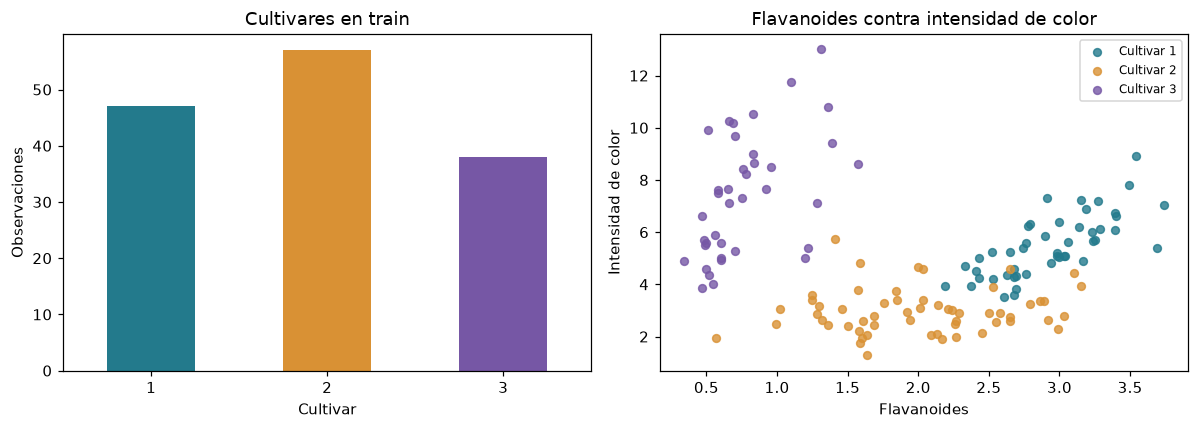

In [7]:
# Un color por cultivar, el mismo en todas las gráficas
colores = {1: "#237A8C", 2: "#D99134", 3: "#7657A5"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
y_train.value_counts().sort_index().plot.bar(ax=ejes[0], color=list(colores.values()), rot=0)
ejes[0].set(title="Cultivares en train", xlabel="Cultivar", ylabel="Observaciones")

# Dos mediciones que, juntas, ya separan bastante a los tres cultivares
for c in (1, 2, 3):
    mascara = y_train == c
    ejes[1].scatter(X_train.loc[mascara, "flavanoids"], X_train.loc[mascara, "color_intensity"],
                    s=26, alpha=.8, color=colores[c], label=f"Cultivar {c}")
ejes[1].set(title="Flavanoides contra intensidad de color", xlabel="Flavanoides", ylabel="Intensidad de color")
ejes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

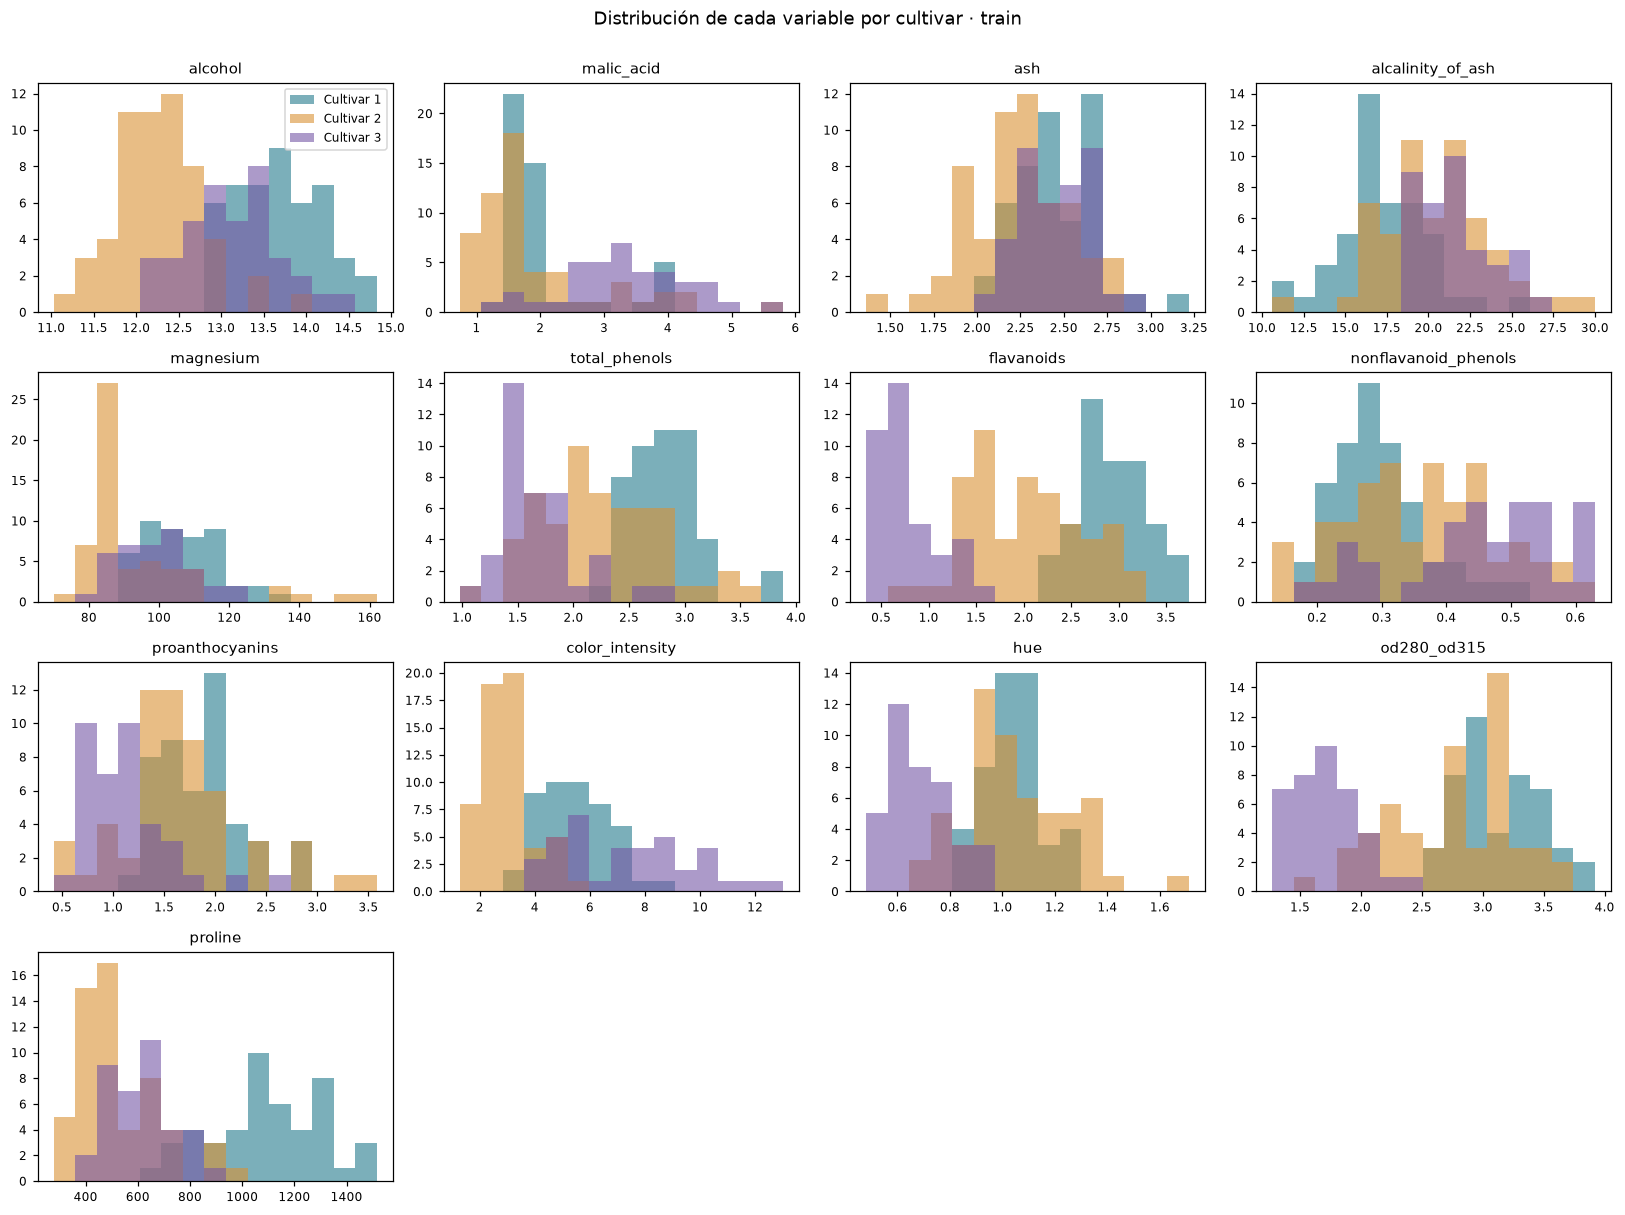

In [8]:
# Histograma de cada variable por cultivar: forma de la distribución y traslape entre cultivares
fig, ejes = plt.subplots(4, 4, figsize=(15, 11))
for ax, col in zip(ejes.ravel(), FEATURES):
    bordes = np.histogram_bin_edges(X_train[col], bins=15)      # mismos bordes para los tres cultivares
    for c in (1, 2, 3):
        ax.hist(X_train.loc[y_train == c, col], bins=bordes, alpha=.6, color=colores[c], label=f"Cultivar {c}")
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
for ax in ejes.ravel()[len(FEATURES):]:
    ax.axis("off")                                              # sobran 3 recuadros de la cuadrícula 4×4
ejes[0, 0].legend(fontsize=8)
fig.suptitle("Distribución de cada variable por cultivar · train", y=1.0)
fig.tight_layout()
plt.show()

## 4. Qué variables separan y cuánto se repiten entre sí

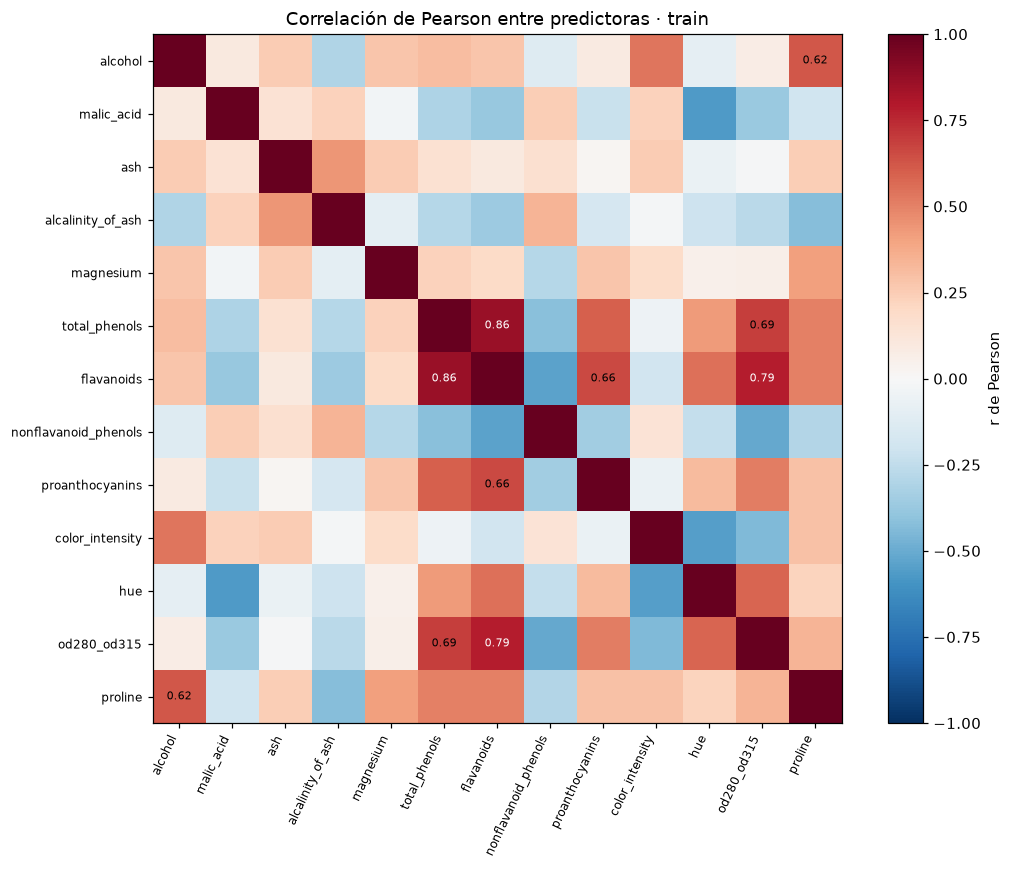

In [9]:
# Correlación de Pearson entre las 13 predictoras (solo train); anoto solo las fuertes
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=65, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        r = corr.iloc[i, j]
        if i != j and abs(r) >= 0.6:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(r) >= 0.75 else "black")
ax.set_title("Correlación de Pearson entre predictoras · train")
fig.colorbar(im, ax=ax, label="r de Pearson")
fig.tight_layout()
plt.show()

In [10]:
# ¿Qué variables separan mejor a los cultivares? F de ANOVA solo con train (exploratorio: el modelo usa las 13)
F, _ = f_classif(X_train, y_train)
ranking = pd.Series(F, index=FEATURES, name="F de ANOVA").sort_values(ascending=False)

# Mediana por cultivar, para leer en qué dirección difieren
medianas = X_train.groupby(y_train).median().T.loc[ranking.index]
medianas.columns = [f"mediana cultivar {c}" for c in medianas.columns]
display(pd.concat([ranking, medianas], axis=1).head(6).round(2))

,F de ANOVA,mediana cultivar 1,mediana cultivar 2,mediana cultivar 3
flavanoids,224.76,2.94,2.01,0.68
proline,161.46,1080.00,495.00,622.50
od280_od315,144.76,3.10,2.81,1.70
color_intensity,103.90,5.25,2.90,7.40
alcohol,98.47,13.68,12.29,13.10
hue,79.53,1.04,1.02,0.66


## 5. Valores extremos (solo train)

Uso la regla de 1.5 × IQR solo para *marcar* observaciones: que un valor quede lejos de la caja no prueba que sea un error químico, y en vinos de tres cultivares distintos es esperable que algunos lo estén. Por eso no los recorto sin evidencia de error.

,celdas marcadas
malic_acid,1
ash,2
alcalinity_of_ash,3
magnesium,3
proanthocyanins,2
color_intensity,2
hue,1


14 celdas marcadas en 7 variables, de 1846 celdas en total.


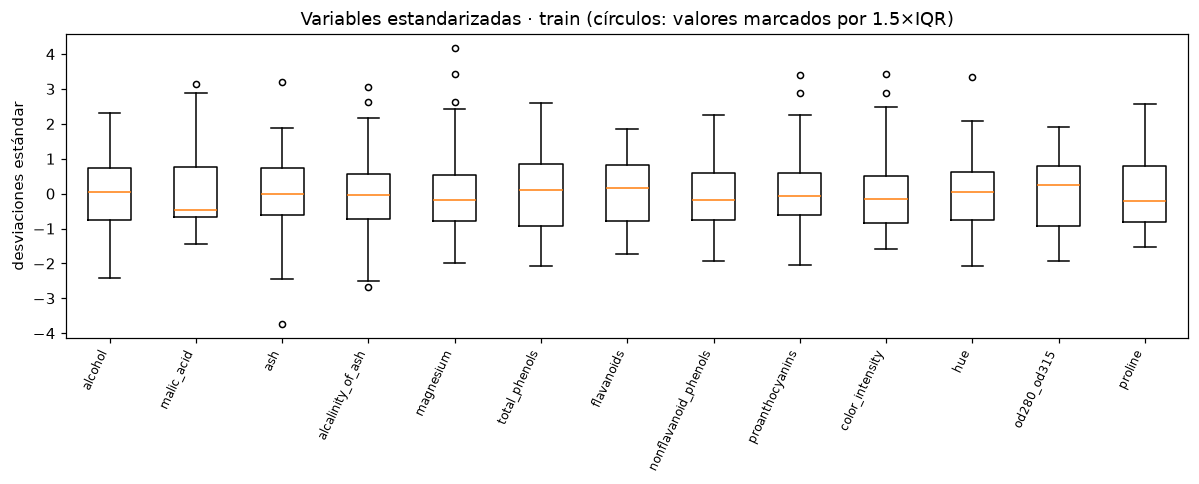

In [11]:
# Al 1.5 le sumo 1e-9 para que un valor justo en la frontera no cambie de lado por redondeo;
# el mismo umbral sirve para la tabla y para el boxplot
UMBRAL_IQR = 1.5 + 1e-9
q1, q3 = X_train.quantile(.25), X_train.quantile(.75)
iqr = q3 - q1
fuera = (X_train < q1 - UMBRAL_IQR * iqr) | (X_train > q3 + UMBRAL_IQR * iqr)
extremos = fuera.sum().rename("celdas marcadas")
display(extremos[extremos > 0].to_frame())
print(f"{int(extremos.sum())} celdas marcadas en {int((extremos > 0).sum())} variables, de {X_train.size} celdas en total.")

# Boxplot de las variables estandarizadas: todos los extremos en una sola escala
z_train = (X_train - X_train.mean()) / X_train.std()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([z_train[c] for c in FEATURES], whis=UMBRAL_IQR, flierprops={"marker": "o", "markersize": 4})
ax.set_xticks(range(1, len(FEATURES) + 1))
ax.set_xticklabels(FEATURES, rotation=65, ha="right", fontsize=8)
ax.set(title="Variables estandarizadas · train (círculos: valores marcados por 1.5×IQR)", ylabel="desviaciones estándar")
fig.tight_layout()
plt.show()

## 6. Lo que la exploración le pasa al script

In [12]:
# Resumen con las cifras de las celdas anteriores (nada escrito a mano)
def unir(items):
    items = list(items)
    return "ninguna" if not items else items[0] if len(items) == 1 else ", ".join(items[:-1]) + " y " + items[-1]

n1, n2, n3 = y_train.value_counts().sort_index().tolist()
sd = X_train.std().sort_values()
c_abs = corr.abs().to_numpy(copy=True)
np.fill_diagonal(c_abs, 0)
i_max, j_max = np.unravel_index(np.argmax(c_abs), c_abs.shape)
fuertes = int((np.triu(c_abs) >= 0.6).sum())                    # pares distintos con |r| >= 0.6

display(Markdown(
    f"- **Métrica.** Las clases están moderadamente desbalanceadas en train ({n1}, {n2} y {n3} vinos): "
    f"`train.py` reporta F1 macro y balanced accuracy además del accuracy.\n"
    f"- **Escalado.** La desviación estándar va de {sd.iloc[0]:.3f} ({sd.index[0]}) a {sd.iloc[-1]:.1f} ({sd.index[-1]}): "
    f"el `StandardScaler` va dentro del Pipeline y se ajusta solo con train.\n"
    f"- **Modelo base.** Las variables con mayor F de ANOVA son {unir(ranking.index[:3])} y flavanoides contra intensidad "
    f"de color ya muestra tres nubes casi separables: un modelo lineal es un baseline razonable.\n"
    f"- **Redundancia.** Hay {fuertes} pares de predictoras con |r| ≥ 0.6; el más fuerte es {FEATURES[i_max]}–{FEATURES[j_max]} "
    f"(r = {corr.iloc[i_max, j_max]:.3f}). Eso motiva comparar la penalización L2 con L1 (`--l1-ratio`), que puede "
    f"prescindir de predictoras redundantes.\n"
    f"- **Extremos.** Los {int(extremos.sum())} valores marcados se conservan: marcar no prueba un error químico."))

- **Métrica.** Las clases están moderadamente desbalanceadas en train (47, 57 y 38 vinos): `train.py` reporta F1 macro y balanced accuracy además del accuracy.
- **Escalado.** La desviación estándar va de 0.119 (nonflavanoid_phenols) a 301.5 (proline): el `StandardScaler` va dentro del Pipeline y se ajusta solo con train.
- **Modelo base.** Las variables con mayor F de ANOVA son flavanoids, proline y od280_od315 y flavanoides contra intensidad de color ya muestra tres nubes casi separables: un modelo lineal es un baseline razonable.
- **Redundancia.** Hay 5 pares de predictoras con |r| ≥ 0.6; el más fuerte es total_phenols–flavanoids (r = 0.861). Eso motiva comparar la penalización L2 con L1 (`--l1-ratio`), que puede prescindir de predictoras redundantes.
- **Extremos.** Los 14 valores marcados se conservan: marcar no prueba un error químico.

Las alternativas de modelo o de preprocesamiento (fuerza y tipo de regularización, optimizador) no se prueban aquí: se comparan como corridas registradas en MLflow con `train.py` y `run_experiments.py`, para que cada número tenga su configuración, su semilla y sus artefactos.

*Creado por Alfonso Boldo.*